# Adaptasi Whisper pada dua video coding

Dua video tutorial Python menjadi sumber audio latih. Subtitle YouTube dipakai sebagai label otomatis sehingga mungkin ada salah dengar atau sedikit selisih waktu. LUMINA menyediakan klip video dan transkrip manusia untuk validasi dan uji pada penutur terpisah. Desain ini memeriksa efek adaptasi terhadap ucapan Indonesia umum. Untuk menilai akurasi khusus coding, gunakan transkrip manual dari video coding lain melalui sel uji tambahan. [Dataset LUMINA v4](https://data.mendeley.com/datasets/8fw93k4rny/4)

## 1. Lingkungan dan konfigurasi

In [1]:
from datetime import datetime
import json
import os
from pathlib import Path
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "requirements-training.txt").is_file())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

SEED = 42
MODE = os.environ.get("NLP_NOTEBOOK_MODE", "smoke")
if MODE not in {"smoke", "pilot"}:
    raise ValueError("NLP_NOTEBOOK_MODE harus smoke atau pilot.")
RUN_ID = datetime.now().strftime("%Y%m%d-%H%M%S-%f")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 120})
print(f"Mode {MODE} | Python {sys.version.split()[0]} | PyTorch {torch.__version__}")

import math
import shutil
from transformers import WhisperForConditionalGeneration, WhisperProcessor, get_linear_schedule_with_warmup
from scripts.notebook_asr import SAMPLE_RATE, encode_clips, evaluate_asr, read_audio, read_manifest, risk_roc

VIDEO = True
local_model = ROOT / "data/raw/models/whisper-base-hf"
BASE_MODEL = os.environ.get("NLP_WHISPER_CHECKPOINT") or (
    str(local_model.relative_to(ROOT)) if (local_model / "model.safetensors").is_file() else "openai/whisper-base"
)
RUN_DIR = ROOT / "outputs/notebooks" / ("whisper-video" if VIDEO else "whisper-nss-id") / RUN_ID
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.manual_seed(SEED)
LR = 1e-5
EPOCHS = 1 if MODE == "smoke" else 3
PATIENCE = 2
if shutil.which("ffmpeg") is None:
    raise RuntimeError("FFmpeg harus tersedia di PATH.")
print("Perangkat", DEVICE, "| Checkpoint", BASE_MODEL, "| Epoch maksimum", EPOCHS)

Mode smoke | Python 3.11.15 | PyTorch 2.15.0+cpu


<akar-repo>\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Perangkat cpu | Checkpoint data\raw\models\whisper-base-hf | Epoch maksimum 1


Eksperimen memakai checkpoint Whisper base untuk bahasa Indonesia. GPU mempercepat forward dan backward, sedangkan CPU dapat menjalankan smoke test. Untuk menguji checkpoint lain, atur `NLP_WHISPER_CHECKPOINT` sebelum memulai kernel. Tetapkan checkpoint yang sama saat membandingkan dua metode adaptasi.

## 2. Siapkan audio tutorial dan acuan manusia

In [2]:
train_path = ROOT / "data/processed/whisper_video/train.csv"
if not train_path.is_file():
    prep_python = ROOT / ".venv/Scripts/python.exe"
    subprocess.run([str(prep_python if prep_python.is_file() else sys.executable), "-m", "scripts.prepare_whisper_video"],
                   cwd=ROOT, check=True)
train_all = read_manifest(train_path, "audio_path")
human = read_manifest(ROOT / "data/processed/lumina/test.csv", "video_path")
speakers = sorted(human["speaker_id"].unique())
assert len(speakers) >= 4 and train_all["video_id"].nunique() == 2
validation_all = human[human["speaker_id"].isin(speakers[: len(speakers) // 2])]
test_all = human[~human["speaker_id"].isin(speakers[: len(speakers) // 2])]
assert set(validation_all["speaker_id"]).isdisjoint(test_all["speaker_id"])
display(train_all.groupby(["video_id", "transcript_source"]).size().rename("jumlah klip"))
display(human.assign(split=np.where(human["id"].isin(validation_all["id"]), "validation", "test"))
        .groupby(["split", "speaker_id"]).size().rename("jumlah klip"))

video_id     transcript_source        
Ar1xxIsyuvI  Subtitle otomatis YouTube    12
JUE9vPXefGI  Subtitle otomatis YouTube     8
Name: jumlah klip, dtype: int64

split       speaker_id
test        P04           12
            P08           12
validation  P01           12
            P03           12
Name: jumlah klip, dtype: int64

FFmpeg mengambil klip audio 12 detik dari dua video. Pemotongan memakai stempel waktu subtitle, lalu pasangan audio dan teks ditulis ke manifest. Seluruh klip tutorial berada di data latih. Rekaman LUMINA dari separuh penutur digunakan untuk validasi dan separuh lainnya untuk uji. Karena domain LUMINA berbeda dari tutorial coding, hasilnya mengukur ucapan umum setelah adaptasi video.

[Video masukan pengguna](https://youtu.be/Ar1xxIsyuvI) · [Video perulangan dengan range](https://youtu.be/JUE9vPXefGI)

## 3. Tetapkan sampel dan periksa sinyal

,klip dipakai,median kata acuan
Latih,4.0,27.5
Validasi,4.0,6.0
Uji,12.0,6.0


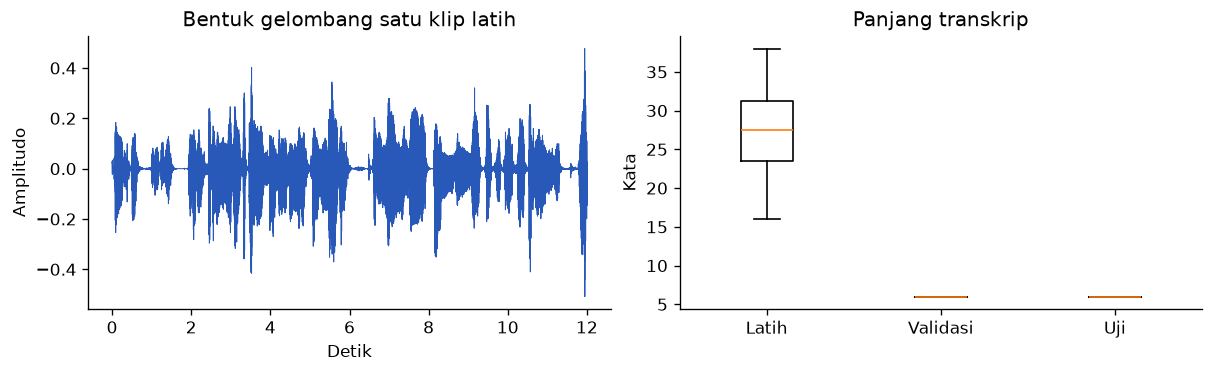

In [3]:
def spread_sample(frame, limit):
    ordered = frame.sort_values("id")
    positions = np.linspace(0, len(ordered) - 1, min(limit, len(ordered)), dtype=int)
    return ordered.iloc[positions].reset_index(drop=True)

if MODE == "smoke":
    grouping = "video_id" if VIDEO else "speaker_id"
    train = spread_sample(train_all, 4)
    if VIDEO:
        assert train[grouping].nunique() == 2
    validation, test_set = spread_sample(validation_all, 4), spread_sample(test_all, 12)
else:
    train = train_all.reset_index(drop=True) if VIDEO else spread_sample(train_all, 48)
    validation, test_set = validation_all.reset_index(drop=True), test_all.reset_index(drop=True)
split_data = {"Latih": train, "Validasi": validation, "Uji": test_set}
display(pd.DataFrame({label: {"klip dipakai": len(frame),
                              "median kata acuan": frame["transcript"].str.split().str.len().median()}
                      for label, frame in split_data.items()}).T)
wave = read_audio(train.iloc[0]["media"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3), layout="constrained")
axes[0].plot(np.arange(len(wave)) / SAMPLE_RATE, wave, color="#2858b8", linewidth=0.6)
axes[0].set(title="Bentuk gelombang satu klip latih", xlabel="Detik", ylabel="Amplitudo")
axes[1].boxplot([frame["transcript"].str.split().str.len() for frame in split_data.values()],
                tick_labels=list(split_data))
axes[1].set(title="Panjang transkrip", ylabel="Kata")
plt.show()

Mode smoke memilih sampel kecil yang tersebar secara deterministik. Mode pilot memperbanyak contoh pelatihan dan memakai semua klip validasi dan uji dari manifest. Grafik gelombang memperlihatkan satu klip setelah audio diubah menjadi mono 16 kHz. Grafik panjang menunjukkan beban target teks pada ketiga split.

## 4. Ekstraksi fitur dan target token

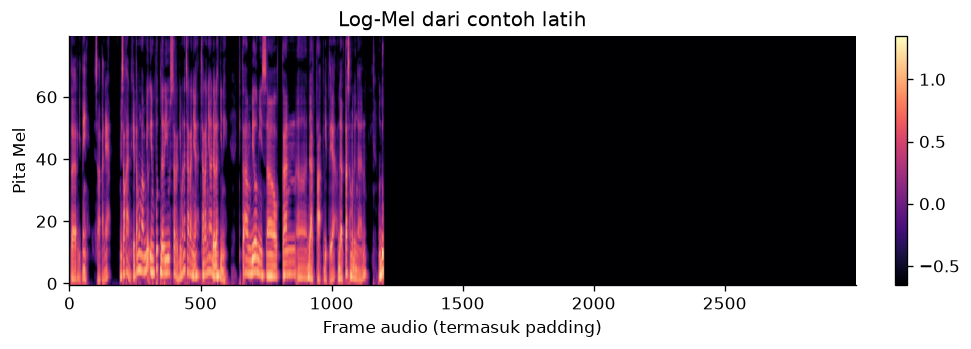

Bentuk fitur (1, 80, 3000) | token target 47


In [4]:
processor = WhisperProcessor.from_pretrained(BASE_MODEL, language="indonesian", task="transcribe")
model = WhisperForConditionalGeneration.from_pretrained(BASE_MODEL).to(DEVICE)
train_clips = encode_clips(train, processor, model)
validation_clips = encode_clips(validation, processor, model)
test_clips = encode_clips(test_set, processor, model)
_, features, labels = train_clips[0]
matrix = features["input_features"][0].numpy()
fig, ax = plt.subplots(figsize=(8, 2.8), layout="constrained")
image = ax.imshow(matrix, origin="lower", aspect="auto", cmap="magma")
ax.set(title="Log-Mel dari contoh latih", xlabel="Frame audio (termasuk padding)", ylabel="Pita Mel")
fig.colorbar(image, ax=ax)
plt.show()
print("Bentuk fitur", tuple(features["input_features"].shape), "| token target", labels.shape[1])

Whisper menerima fitur log-Mel dari gelombang audio. Processor menyiapkan fitur berukuran tetap dan mask audio. Tokenizer membentuk target bahasa Indonesia untuk tugas transkripsi. Token pembuka decoder dilepas dari label karena model menambahkannya ketika menggeser target untuk pelatihan.

## 5. Ukur baseline sebelum fine-tuning

In [5]:
base_validation, base_validation_rows = evaluate_asr(model, processor, validation_clips, DEVICE)
base_metrics, base_rows = evaluate_asr(model, processor, test_clips, DEVICE)
display(pd.DataFrame([base_validation, base_metrics], index=["Validasi", "Uji"]))
display(base_rows[["id", "reference", "prediction", "wer", "cer"]].head(3))

The following generation flags are not valid and may be ignored: ['output_scores']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


,wer,cer
Validasi,0.583333,0.262069
Uji,0.569444,0.214118


,id,reference,prediction,wer,cer
0,P04_S1233,gutik enam solusi ungu dari loket,Kutik 6 solusi umur dari loket.,0.500000,0.242424
1,P04_S1246,taruh satu fonemik indigo dari hotel,Taruh satu polenemik indikut dari hotel.,0.333333,0.166667
2,P04_S1813,baca delapan difusi indigo di bekasi,"Baca telapan, Tifusi Indiko di pekasih.",0.666667,0.138889


Baseline memakai checkpoint awal dengan greedy decoding. WER menggunakan substitusi, penghapusan, dan penyisipan kata dibagi jumlah kata acuan. CER memakai satuan karakter. Referensi dan prediksi menjalani normalisasi yang sama. WER dapat melampaui 100% jika jumlah kesalahan, termasuk sisipan, lebih besar daripada kata acuan. Skor uji baseline hanya dicatat sebagai pembanding akhir dan tidak dipakai untuk memilih epoch.

## 6. Adaptasi decoder dan pilih epoch

In [6]:
model.requires_grad_(False)
last_layer = model.model.decoder.layers[-1]
for attention in (last_layer.self_attn, last_layer.encoder_attn):
    attention.q_proj.requires_grad_(True)
    attention.v_proj.requires_grad_(True)
learnable = {name: parameter for name, parameter in model.named_parameters() if parameter.requires_grad}
print("Parameter trainable", f"{sum(p.numel() for p in learnable.values()):,}")
optimizer = torch.optim.AdamW(learnable.values(), lr=LR, weight_decay=0.01, foreach=False)
updates = EPOCHS * len(train_clips)
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.10 * updates), updates)
history_rows = []
best = None
for epoch in range(1, EPOCHS + 1):
    model.train()
    losses = []
    order = np.random.default_rng(SEED + epoch).permutation(len(train_clips))
    for index in order:
        _, features, labels = train_clips[index]
        optimizer.zero_grad(set_to_none=True)
        loss = model(**features.to(DEVICE), labels=labels.to(DEVICE), use_cache=False).loss
        if not torch.isfinite(loss):
            raise RuntimeError("Loss tidak finite.")
        loss.backward()
        torch.nn.utils.clip_grad_norm_(learnable.values(), 1.0, error_if_nonfinite=True)
        optimizer.step()
        scheduler.step()
        losses.append(loss.item())
    validation_scores, _ = evaluate_asr(model, processor, validation_clips, DEVICE)
    record = {"epoch": epoch, "loss_latih": float(np.mean(losses)), "lr_akhir": scheduler.get_last_lr()[0],
              **{f"val_{name}": value for name, value in validation_scores.items()}}
    history_rows.append(record)
    print(record)
    if best is None or (record["val_wer"], record["val_cer"]) < (best["val_wer"], best["val_cer"]):
        best = {**record, "weights": {name: p.detach().cpu().clone() for name, p in learnable.items()}}
    if epoch - best["epoch"] >= PATIENCE:
        break
with torch.no_grad():
    for name, parameter in learnable.items():
        parameter.copy_(best["weights"][name])
RUN_DIR.mkdir(parents=True, exist_ok=False)
model.save_pretrained(RUN_DIR / "checkpoint")
processor.save_pretrained(RUN_DIR / "checkpoint")
history = pd.DataFrame(history_rows)
history.to_csv(RUN_DIR / "history.csv", index=False)
print("Epoch terpilih", best["epoch"])

Parameter trainable 1,050,624


{'epoch': 1, 'loss_latih': 5.029304385185242, 'lr_akhir': 0.0, 'val_wer': 0.5833333333333334, 'val_cer': 0.2620689655172414}


<akar-repo>\.venv\Lib\site-packages\transformers\modeling_utils.py:3918: UserWarning: Moving the following attributes in the config to the generation config: {'max_length': 448, 'suppress_tokens': [1, 2, 7, 8, 9, 10, 14, 25, 26, 27, 28, 29, 31, 58, 59, 60, 61, 62, 63, 90, 91, 92, 93, 359, 503, 522, 542, 873, 893, 902, 918, 922, 931, 1350, 1853, 1982, 2460, 2627, 3246, 3253, 3268, 3536, 3846, 3961, 4183, 4667, 6585, 6647, 7273, 9061, 9383, 10428, 10929, 11938, 12033, 12331, 12562, 13793, 14157, 14635, 15265, 15618, 16553, 16604, 18362, 18956, 20075, 21675, 22520, 26130, 26161, 26435, 28279, 29464, 31650, 32302, 32470, 36865, 42863, 47425, 49870, 50254, 50258, 50358, 50359, 50360, 50361, 50362], 'begin_suppress_tokens': [220, 50257]}. You are seeing this warning because you've set generation parameters in the model config, as opposed to in the generation config.
  warnings.warn(


Epoch terpilih 1


Encoder dan sebagian besar decoder dibekukan. Optimizer memperbarui proyeksi query dan value pada attention di lapisan decoder terakhir. AdamW menggunakan learning rate awal 1e-5, warmup maksimal sekitar 10% langkah, lalu penurunan linear. Jika dua epoch berturut-turut tidak memperbaiki WER validasi, pelatihan berhenti. CER memecahkan nilai seri. Bobot epoch terbaik dipulihkan, kemudian lengkap dengan processor disimpan sebagai checkpoint Transformers.

## 7. Grafik loss, WER, dan CER validasi

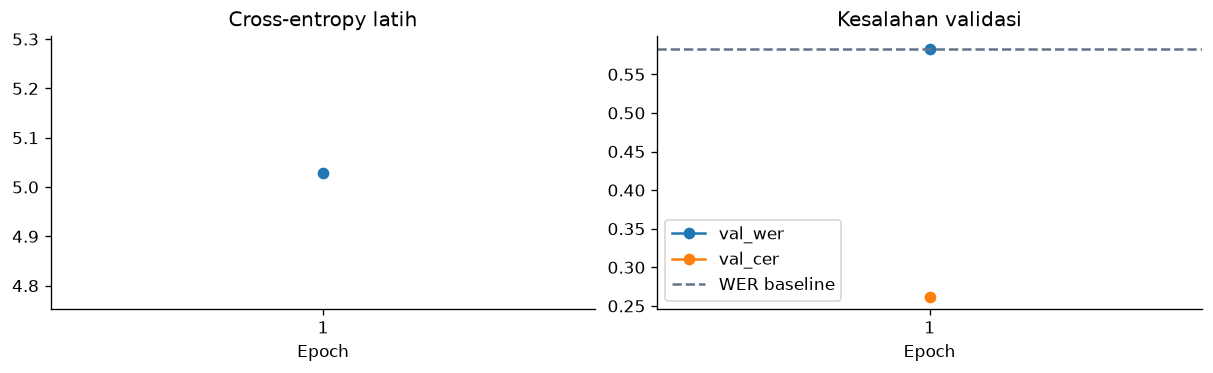

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3), layout="constrained")
history.plot(x="epoch", y="loss_latih", ax=axes[0], marker="o", legend=False, title="Cross-entropy latih")
history.plot(x="epoch", y=["val_wer", "val_cer"], ax=axes[1], marker="o", title="Kesalahan validasi")
axes[1].axhline(base_validation["wer"], linestyle="--", color="#64748b", label="WER baseline")
axes[1].legend()
for ax in axes:
    ax.set_xticks(history["epoch"])
    ax.set_xlabel("Epoch")
plt.show()

Penurunan loss latih menunjukkan model lebih cocok dengan label audio latih. Periksa WER dan CER validasi untuk mengetahui dampaknya pada suara lain. Ini penting saat label latih berasal dari subtitle otomatis karena model juga dapat belajar kesalahan subtitle.

## 8. Bandingkan hasil uji dan jenis kesalahan

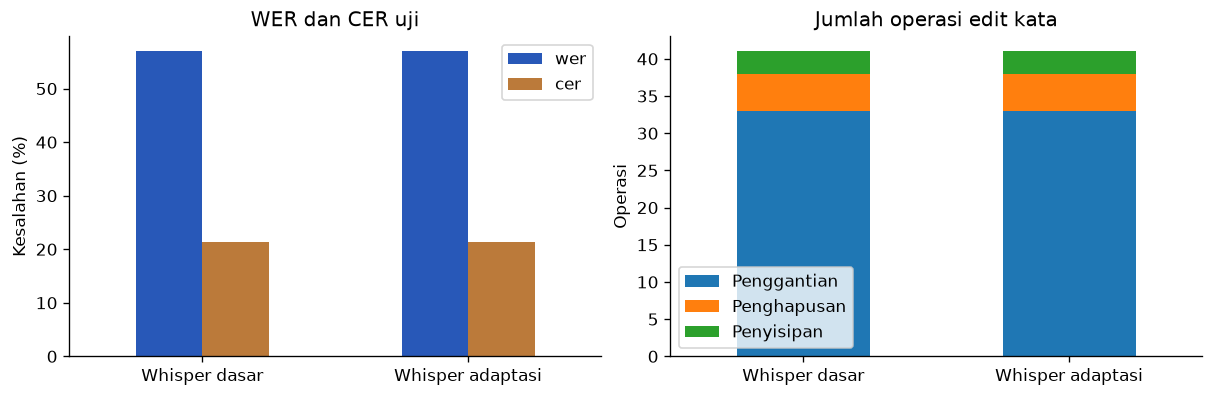

,wer,cer
Whisper dasar,0.5694,0.2141
Whisper adaptasi,0.5694,0.2141


,id,reference,prediction_dasar,prediction_adaptasi,delta_wer
0,P04_S1233,gutik enam solusi ungu dari loket,Kutik 6 solusi umur dari loket.,Kutik 6 solusi umur dari loket.,0.0
1,P04_S1246,taruh satu fonemik indigo dari hotel,Taruh satu polenemik indikut dari hotel.,Taruh satu polenemik indikut dari hotel.,0.0
2,P04_S1813,baca delapan difusi indigo di bekasi,"Baca telapan, Tifusi Indiko di pekasih.","Baca telapan, Tifusi Indiko di pekasih.",0.0
3,P04_S1888,coba sepuluh nubuwat kuning di sekolah,Coba sapuluh lu buat kuning di sekolah.,Coba sapuluh lu buat kuning di sekolah.,0.0
4,P04_S2352,ambil delapan fonemik hijau dari negeri,Ambil 8 fon emik hijau dari Nakhiri.,Ambil 8 fon emik hijau dari Nakhiri.,0.0
5,P04_S518,lihat dua mukjizat ungu di sekolah,lihat dua mukjisat umur di sepola,lihat dua mukjisat umur di sepola,0.0


342

In [8]:
tuned_metrics, tuned_rows = evaluate_asr(model, processor, test_clips, DEVICE)
comparison = pd.DataFrame([base_metrics, tuned_metrics], index=["Whisper dasar", "Whisper adaptasi"])
error_columns = ["Penggantian", "Penghapusan", "Penyisipan"]
counts = pd.DataFrame([base_rows[error_columns].sum(), tuned_rows[error_columns].sum()], index=comparison.index)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), layout="constrained")
comparison.mul(100).plot.bar(ax=axes[0], rot=0, color=["#2858b8", "#bb7a3a"], title="WER dan CER uji")
axes[0].set_ylabel("Kesalahan (%)")
counts.plot.bar(ax=axes[1], stacked=True, rot=0, title="Jumlah operasi edit kata")
axes[1].set_ylabel("Operasi")
plt.show()
display(comparison.round(4))
audit = tuned_rows.merge(base_rows[["id", "wer", "prediction"]], on="id", suffixes=("_adaptasi", "_dasar"))
audit["delta_wer"] = audit["wer_adaptasi"] - audit["wer_dasar"]
display(audit[["id", "reference", "prediction_dasar", "prediction_adaptasi", "delta_wer"]].head(6))
audit.to_csv(RUN_DIR / "test_predictions.csv", index=False)
metrics = {"checkpoint_initial": BASE_MODEL, "mode": MODE, "seed": SEED, "best_epoch": best["epoch"],
           "sizes": {label: len(frame) for label, frame in split_data.items()},
           "base": base_metrics, "tuned": tuned_metrics}
(RUN_DIR / "metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")

Kedua checkpoint memakai contoh uji yang sama. Selisih WER yang negatif pada tabel berarti adaptasi mengurangi kesalahan pada contoh itu. Grafik operasi edit membantu membedakan kata yang tertukar, hilang, atau ditambah. Periksa kolom referensi dan prediksi untuk melihat apakah perubahan memengaruhi istilah penting.

## 9. ROC untuk mendeteksi transkrip berisiko

In [9]:
fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
plotted = False
for name, frame in (("Whisper dasar", base_rows), ("Whisper adaptasi", tuned_rows)):
    result = risk_roc(frame, threshold=0.30)
    if result is None:
        print(f"{name}: ROC tidak tersedia karena sampel dengan skor confidence belum memuat kedua kelas.")
        continue
    fpr, tpr, auc, n = result
    ax.plot(fpr, tpr, marker=".", label=f"{name} · AUC {auc:.2f} · n={n}")
    plotted = True
if plotted:
    ax.plot([0, 1], [0, 1], "--", color="#64748b", linewidth=1)
    ax.set(xlabel="False positive rate", ylabel="True positive rate", title="Deteksi klip dengan WER ≥ 30%")
    ax.legend(loc="lower right")
    plt.show()
else:
    plt.close(fig)

Whisper dasar: ROC tidak tersedia karena sampel dengan skor confidence belum memuat kedua kelas.
Whisper adaptasi: ROC tidak tersedia karena sampel dengan skor confidence belum memuat kedua kelas.


Pada tugas tambahan ini, label positif berarti transkrip satu klip memiliki WER minimal 30% terhadap referensi manusia. Skor risiko berasal dari rendahnya rata-rata log probabilitas token hasil decoding. ROC mengukur seberapa baik skor ini mengurutkan klip berisiko. AUC pada sampel kecil hanya bersifat eksploratif. Kurva memerlukan setidaknya satu contoh dari setiap kelas.

## 10. Uji opsional pada video coding baru

In [10]:
extra = os.environ.get("NLP_WHISPER_VIDEO_TEST_CSV")
if extra:
    coding_test = read_manifest(Path(extra).resolve(), "audio_path")
    if set(coding_test["video_id"]) & set(train["video_id"]):
        raise ValueError("Video uji coding harus berbeda dari semua video latih.")
    coding_clips = encode_clips(coding_test, processor, model)
    coding_metrics, coding_predictions = evaluate_asr(model, processor, coding_clips, DEVICE)
    display(pd.Series(coding_metrics))
    display(coding_predictions[["id", "video_id", "reference", "prediction", "wer"]])
else:
    print("Uji coding tambahan belum dijalankan. Lihat format manifest di notebooks/README.md.")

Uji coding tambahan belum dijalankan. Lihat format manifest di notebooks/README.md.


Uji ini membutuhkan klip berpenanda waktu dari video coding yang tidak ikut pelatihan beserta transkrip yang sudah diverifikasi manusia. Hasilnya mengukur domain coding secara lebih langsung. Untuk membandingkan model dasar pada data tambahan yang sama, jalankan evaluasi terpisah memakai checkpoint awal.

## Kesimpulan yang bisa ditulis

Laporkan jumlah klip dan penutur, checkpoint awal, epoch terpilih, serta WER dan CER sebelum dan sesudah adaptasi. Ambil contoh kesalahan dari tabel dan jelaskan pengaruhnya pada pemahaman. Pisahkan temuan pada ucapan umum dari temuan pada tutorial coding.

## Hasil smoke lokal yang ditampilkan

Pada 12 klip uji, WER berubah dari 56.94% menjadi 56.94% dan CER dari 21.41% menjadi 21.41%. Hasil satu epoch dan empat klip latih ini mengonfirmasi bahwa pelatihan, penyimpanan checkpoint, dan evaluasi dapat dijalankan. Klip uji berasal dari LUMINA. Hasil ini belum mengukur WER pada video coding independen. Semua klip uji memiliki WER di atas 30%, sehingga kurva ROC pada ambang tersebut memerlukan contoh tambahan dari kelas WER rendah.